# Hierarchical Bayesian A/B Test with PyStan
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Business problem
A company ran an A/B test of a new checkout flow across **8 customer segments**. Some segments are tiny, so their raw conversion lifts are very noisy. Stakeholders want to know:

1. Does the new flow improve conversion overall, and by how much?
2. Which segments benefit, and how confident are we?
3. What is the probability the lift exceeds the minimum worthwhile effect (+0.5 percentage points)?

## Why Bayesian and hierarchical?
- **Partial pooling** shrinks noisy small-segment estimates toward the global mean, reducing false positives from slicing the data many ways.
- **Posteriors** give direct probability statements ("94% chance lift > 0.5pp") that map to business decisions better than p-values.

## Modelling choices
- Binomial likelihood with a logit link
- Segment-level baseline (`alpha_j`) and treatment effect (`beta_j`), each drawn from a population distribution
- Non-centered parameterization to avoid funnel-shaped geometry and divergences
- Weakly-informative priors
- Posterior predictive checks, convergence diagnostics and PSIS-LOO

> **Colab tip:** the first Stan compile takes about a minute. Run the install cell, then use *Runtime → Restart session* only if you see import errors.

## 1. Setup

In [1]:
!pip install -q pystan nest_asyncio "arviz<1" matplotlib pandas numpy

In [2]:
import nest_asyncio
nest_asyncio.apply()   # required: PyStan 3 uses asyncio, which Colab/Jupyter already runs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
import stan

RNG = np.random.default_rng(42)

## 2. Simulate data with a known ground truth
Simulating lets us check that the model actually recovers the true effects. Segment sizes are deliberately imbalanced so some segments are noisy.

In [3]:
J = 8
segments = [f"Segment {chr(65 + j)}" for j in range(J)]

true_mu_a, true_tau_a = -2.0, 0.6      # baseline log-odds (~12% conversion)
true_mu_b, true_tau_b = 0.15, 0.12     # average treatment effect on log-odds

true_alpha = RNG.normal(true_mu_a, true_tau_a, J)
true_beta = RNG.normal(true_mu_b, true_tau_b, J)

n_per_arm = np.array([12000, 8000, 5000, 3000, 1500, 800, 400, 200])


def inv_logit(x):
    return 1 / (1 + np.exp(-x))


rows = []
for j in range(J):
    for treat in (0, 1):
        p = inv_logit(true_alpha[j] + true_beta[j] * treat)
        succ = RNG.binomial(n_per_arm[j], p)
        rows.append(dict(seg=j + 1, segment=segments[j], treat=treat,
                         trials=int(n_per_arm[j]), succ=int(succ)))

df = pd.DataFrame(rows)
df["rate"] = df["succ"] / df["trials"]

# Raw (no-pooling) lift per segment, for comparison with the Bayesian estimate
raw = df.pivot(index="segment", columns="treat", values="rate")
raw["raw_lift"] = raw[1] - raw[0]
true_lift = inv_logit(true_alpha + true_beta) - inv_logit(true_alpha)

df

,seg,segment,treat,trials,succ,rate
0,1,Segment A,0,12000,1732,0.144333
1,1,Segment A,1,12000,1889,0.157417
2,2,Segment B,0,8000,516,0.064500
3,2,Segment B,1,8000,613,0.076625
4,3,Segment C,0,5000,848,0.169600
5,3,Segment C,1,5000,1111,0.222200
6,4,Segment D,0,3000,556,0.185333
7,4,Segment D,1,3000,702,0.234000
8,5,Segment E,0,1500,70,0.046667
9,5,Segment E,1,1500,67,0.044667


## 3. The Stan model
Key points:
- `z_a`, `z_b` are standard-normal offsets (**non-centered parameterization**), so the sampler doesn't struggle when `tau` is small.
- `generated quantities` computes the business metric (absolute lift), posterior predictive draws and the pointwise log-likelihood for LOO.

In [4]:
stan_code = """
data {
  int<lower=1> J;                          // segments
  int<lower=1> N;                          // segment-arm rows
  array[N] int<lower=1, upper=J> seg;
  vector[N] treat;                         // 0 = control, 1 = treatment
  array[N] int<lower=1> trials;
  array[N] int<lower=0> succ;
}
parameters {
  real mu_a;                               // population mean baseline (logit)
  real mu_b;                               // population mean treatment effect (logit)
  real<lower=0> tau_a;                     // between-segment sd of baselines
  real<lower=0> tau_b;                     // between-segment sd of effects
  vector[J] z_a;                           // non-centered offsets
  vector[J] z_b;
}
transformed parameters {
  vector[J] alpha = mu_a + tau_a * z_a;    // segment baselines
  vector[J] beta  = mu_b + tau_b * z_b;    // segment treatment effects
}
model {
  // Weakly-informative priors
  mu_a  ~ normal(-2, 1.5);
  mu_b  ~ normal(0, 0.5);
  tau_a ~ normal(0, 1);                    // half-normal due to lower bound
  tau_b ~ normal(0, 0.5);
  z_a   ~ std_normal();
  z_b   ~ std_normal();

  succ ~ binomial_logit(trials, alpha[seg] + beta[seg] .* treat);
}
generated quantities {
  vector[J] lift;                          // absolute lift in conversion rate
  real overall_lift;                       // lift for the average segment
  real new_segment_lift;                   // lift for a never-seen segment
  array[N] int succ_rep;                   // posterior predictive draws
  vector[N] log_lik;                       // for LOO / WAIC

  for (j in 1:J)
    lift[j] = inv_logit(alpha[j] + beta[j]) - inv_logit(alpha[j]);

  overall_lift = inv_logit(mu_a + mu_b) - inv_logit(mu_a);

  {
    real a_new = normal_rng(mu_a, tau_a);
    real b_new = normal_rng(mu_b, tau_b);
    new_segment_lift = inv_logit(a_new + b_new) - inv_logit(a_new);
  }

  for (n in 1:N) {
    real eta = alpha[seg[n]] + beta[seg[n]] * treat[n];
    succ_rep[n] = binomial_rng(trials[n], inv_logit(eta));
    log_lik[n]  = binomial_logit_lpmf(succ[n] | trials[n], eta);
  }
}
"""

stan_data = dict(
    J=J,
    N=len(df),
    seg=df["seg"].tolist(),
    treat=df["treat"].astype(float).tolist(),
    trials=df["trials"].tolist(),
    succ=df["succ"].tolist(),
)

In [6]:
!pip install -q cmdstanpy
import cmdstanpy
cmdstanpy.install_cmdstan(progress=False)

CmdStan install directory: /root/.cmdstan
Installing CmdStan version: 2.40.0
Download successful, file: /tmp/tmpq__8__2l
Extracting distribution
Unpacked download as cmdstan-2.40.0
Building version cmdstan-2.40.0, may take several minutes, depending on your system.
Installed cmdstan-2.40.0
Test model compilation


True

## 4. Fit the model (compiles the first time, then samples 4 chains)

In [7]:
from cmdstanpy import CmdStanModel

NUM_CHAINS, NUM_SAMPLES = 4, 1000

with open("ab_model.stan", "w") as f:
    f.write(stan_code)

model = CmdStanModel(stan_file="ab_model.stan")
fit = model.sample(
    data=stan_data,
    chains=NUM_CHAINS,
    iter_warmup=1000,
    iter_sampling=NUM_SAMPLES,
    adapt_delta=0.95,    # raise to 0.99 if you see divergences
    seed=1,
)


def draws(name):
    """CmdStanPy returns (chains*draws, ...); reshape to ArviZ's (chain, draw, ...)."""
    arr = np.asarray(fit.stan_variable(name))
    if arr.ndim == 1:
        return arr.reshape(NUM_CHAINS, NUM_SAMPLES)
    return arr.reshape(NUM_CHAINS, NUM_SAMPLES, -1)

chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

Exception: binomial_logit_lpmf: Probability parameter[1] is -nan, but must be finite! (in 'ab_model.stan', line 31, column 2 to column 65)
Exception: binomial_logit_lpmf: Probability parameter[1] is -inf, but must be finite! (in 'ab_model.stan', line 31, column 2 to column 65)
	Exception: binomial_logit_lpmf: Probability parameter[1] is -inf, but must be finite! (in 'ab_model.stan', line 31, column 2 to column 65)
Exception: binomial_logit_lpmf: Probability parameter[1] is -inf, but must be finite! (in 'ab_model.stan', line 31, column 2 to column 65)
	Exception: binomial_logit_lpmf: Probability parameter[1] is -inf, but must be finite! (in 'ab_model.stan', line 31, column 2 to column 65)
Consider re-running with show_console=True if the above output is unclear!


## 5. Diagnostics
Never skip these. You want **R-hat ≈ 1.00**, **ESS in the hundreds or more**, and **zero divergent transitions**.

In [9]:
idata = az.from_dict(
    posterior={k: draws(k) for k in
               ["mu_a", "mu_b", "tau_a", "tau_b", "alpha", "beta",
                "lift", "overall_lift", "new_segment_lift"]},
    posterior_predictive={"succ": draws("succ_rep")},
    log_likelihood={"succ": draws("log_lik")},
    observed_data={"succ": df["succ"].to_numpy()},
)

summary = az.summary(idata, var_names=["mu_a", "mu_b", "tau_a", "tau_b",
                                       "overall_lift"], round_to=4)
display(summary)

divergent = fit.method_variables()["divergent__"].sum()#divergent = fit.to_frame()["divergent__"].sum()
print(f"Divergent transitions: {int(divergent)}")
print(f"Max r_hat: {az.rhat(idata).to_array().max().item():.3f}")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_a,-2.1773,0.2560,-2.6491,-1.6695,0.0088,0.0059,837.3857,1242.1311,1.0048
mu_b,0.1892,0.0716,0.0424,0.3107,0.0019,0.0028,1721.2907,1451.6717,1.0021
tau_a,0.7107,0.2234,0.3815,1.1168,0.0077,0.0064,816.2239,1665.6537,1.0103
tau_b,0.1435,0.0768,0.0328,0.2786,0.0022,0.0026,1137.9000,1576.5397,1.0019
overall_lift,0.0190,0.0085,0.0041,0.0356,0.0002,0.0003,1258.6097,1548.3656,1.0020


Divergent transitions: 0
Max r_hat: 1.010


## 6. Business answers
Translate the posterior into decision metrics a stakeholder can act on.

In [10]:
overall = draws("overall_lift").ravel()
lift = draws("lift").reshape(-1, J)
MIN_EFFECT = 0.005  # +0.5 percentage points = minimum worthwhile lift

print("=== Overall decision metrics ===")
print(f"Posterior mean lift:   {overall.mean() * 100:.2f} pp")
print(f"94% credible interval: [{np.percentile(overall, 3) * 100:.2f}, "
      f"{np.percentile(overall, 97) * 100:.2f}] pp")
print(f"P(lift > 0):           {(overall > 0).mean():.3f}")
print(f"P(lift > {MIN_EFFECT * 100:.1f}pp):      {(overall > MIN_EFFECT).mean():.3f}")

=== Overall decision metrics ===
Posterior mean lift:   1.90 pp
94% credible interval: [0.38, 3.55] pp
P(lift > 0):           0.986
P(lift > 0.5pp):      0.961


In [11]:
seg_table = pd.DataFrame({
    "n_per_arm": n_per_arm,
    "raw_lift_pp": raw["raw_lift"].to_numpy() * 100,
    "bayes_lift_pp": lift.mean(0) * 100,
    "true_lift_pp": true_lift * 100,
    "P(lift>0)": (lift > 0).mean(0),
    "P(lift>MDE)": (lift > MIN_EFFECT).mean(0),
}, index=segments).round(3)

seg_table

,n_per_arm,raw_lift_pp,bayes_lift_pp,true_lift_pp,P(lift>0),P(lift>MDE)
Segment A,12000,1.308,1.450,1.876,0.999,0.980
Segment B,8000,1.212,1.212,0.307,0.999,0.973
Segment C,5000,5.260,4.894,4.002,1.000,1.000
Segment D,3000,4.867,4.535,4.063,1.000,1.000
Segment E,1500,-0.200,0.404,0.657,0.781,0.469
Segment F,800,2.125,1.423,1.779,0.972,0.904
Segment G,400,3.250,2.737,2.474,0.964,0.932
Segment H,200,-3.000,0.919,0.433,0.786,0.687


Notice how the **smallest segments** (G, H) have raw lifts that swing wildly, while the Bayesian estimates are pulled toward the overall mean. That is partial pooling at work.

## 7. Model comparison with PSIS-LOO
Higher `elpd_loo` means better out-of-sample predictive accuracy. As an extension, fit a complete-pooling model (a single `beta` for all segments) and compare the two with `az.compare`.

In [12]:
loo = az.loo(idata, var_name="succ")
print(loo)

/usr/local/lib/python3.13/dist-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


Computed from 4000 posterior samples and 16 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -72.69     3.43
p_loo       10.97        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)        3   18.8%
   (0.70, 1]   (bad)        12   75.0%
   (1, Inf)   (very bad)    1    6.2%



## 8. Visualizations

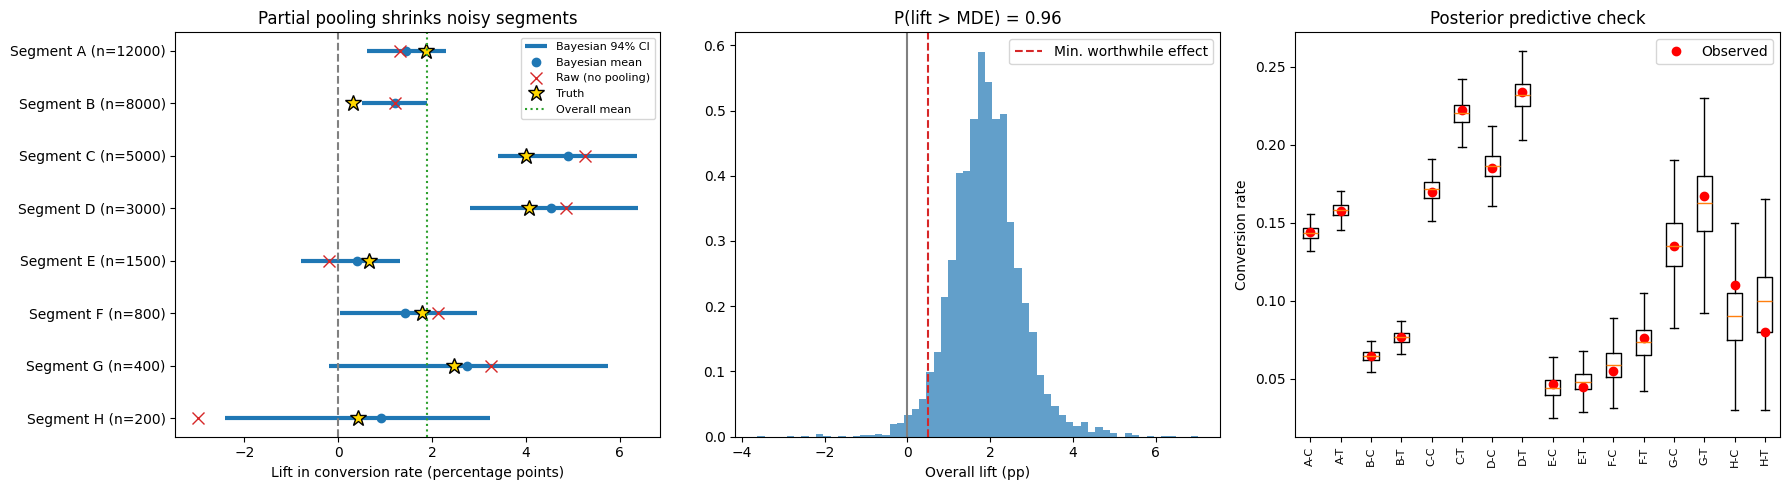

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Shrinkage forest plot
ax = axes[0]
y = np.arange(J)
lo, hi = np.percentile(lift, [3, 97], axis=0) * 100
ax.hlines(y, lo, hi, color="C0", lw=3, label="Bayesian 94% CI")
ax.plot(lift.mean(0) * 100, y, "o", color="C0", label="Bayesian mean")
ax.plot(raw["raw_lift"].to_numpy() * 100, y, "x", color="C3", ms=9,
        label="Raw (no pooling)")
ax.plot(true_lift * 100, y, "*", color="gold", ms=12, mec="k", label="Truth")
ax.axvline(0, color="grey", ls="--")
ax.axvline(overall.mean() * 100, color="C2", ls=":", label="Overall mean")
ax.set_yticks(y)
ax.set_yticklabels([f"{s} (n={n})" for s, n in zip(segments, n_per_arm)])
ax.invert_yaxis()
ax.set_xlabel("Lift in conversion rate (percentage points)")
ax.set_title("Partial pooling shrinks noisy segments")
ax.legend(fontsize=8)

# (b) Posterior of overall lift
ax = axes[1]
ax.hist(overall * 100, bins=60, color="C0", alpha=0.7, density=True)
ax.axvline(MIN_EFFECT * 100, color="C3", ls="--", label="Min. worthwhile effect")
ax.axvline(0, color="grey")
ax.set_xlabel("Overall lift (pp)")
ax.set_title(f"P(lift > MDE) = {(overall > MIN_EFFECT).mean():.2f}")
ax.legend()

# (c) Posterior predictive check
ax = axes[2]
rep_rate = draws("succ_rep").reshape(-1, len(df)) / df["trials"].to_numpy()
ax.boxplot(rep_rate, positions=np.arange(len(df)), showfliers=False, widths=0.5)
ax.plot(np.arange(len(df)), df["rate"].to_numpy(), "ro", label="Observed")
ax.set_xticks(np.arange(len(df)))
ax.set_xticklabels([f"{s[-1]}-{'T' if t else 'C'}"
                    for s, t in zip(df["segment"], df["treat"])],
                   rotation=90, fontsize=8)
ax.set_ylabel("Conversion rate")
ax.set_title("Posterior predictive check")
ax.legend()

plt.tight_layout()
plt.show()

## 9. Summary for stakeholders
> The new checkout flow is estimated to lift conversion by **X=1.90 pp** (94% CI: [low=0.38, high=3.55]), with a **Y%= P(lift > 0.5pp)=0.961 ** probability of exceeding our +0.5pp threshold. Gains are consistent across segments; apparent differences in the smallest segments are mostly noise and have been shrunk toward the overall effect.

X, Y and the interval are obtained from Section 6 above in the notebook where X is the posterior mean lift and Y is P(lift > 0.5pp)

## Ideas to extend this
- Replace the simulated data with a real dataset (e.g. Criteo uplift, Cookie Cats)
- Fit a complete-pooling model and compare with `az.compare`
- Run a prior sensitivity analysis
- Add covariates (device, region) to the linear predictor